# CatalogIQ - Notebook 05: Answering shopper questions from real reviews

**The business problem.** A shopper looking at a shirt asks "does it run big?" or "is the strap machine washable?". The answer is
usually buried in hundreds of reviews. A chatbot that answers from general knowledge will sometimes make things up, and a made-up
"yes, it is waterproof" costs a return and a bad review. So this notebook asks: **can a small local model answer shopper questions
using only the reviews of the product being viewed, quote its sources, and say "not enough reviews mention this" when the evidence is
not there?**

**How to read it.** Every step says WHAT we did, WHY it matters to the business and WHAT WE LEARNED. The numbers in the "learned"
boxes were printed by the code just above them. All logic lives in `src/catalogiq/rag/`; the notebook only loads saved results.
The 60-question evaluation takes about 25 minutes on this laptop's CPU, so it is run once by `scripts/evaluate_qa.py` and this
notebook reads its outputs.

**Honest scope.** 20 products, 60 questions (45 answerable, 15 unanswerable), one local 3B model (`llama3.2:3b`), one person's labels.
The system was designed while looking at these same 60 questions, so treat every number as a development estimate, not a guarantee.

In [1]:
import json, warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from catalogiq.config import get_qa_config, resolve_path
from catalogiq.rag.eval_qa import (
    gate_rates, ground_truth, load_questions, review_texts, validate_questions,
)
from catalogiq.rag.reviews_index import chunk_stats, load_chunks

pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 140)
cfg = get_qa_config()
OUT = resolve_path(cfg["paths"]["eval_dir"])
FIG = resolve_path("reports/figures")
M = json.loads((OUT / "metrics.json").read_text(encoding="utf-8"))
reviews = review_texts()
text_of = dict(zip(reviews["review_id"], reviews["full"]))
answers = [json.loads(x) for x in (OUT / "answers.jsonl").read_text(encoding="utf-8").splitlines()]
by_id = {a["id"]: a for a in answers}
judge = {j["id"]: j["judge"] for j in map(json.loads, (OUT / "faithfulness.jsonl").read_text(encoding="utf-8").splitlines())}

## 1. The index: every review, cut into searchable pieces

**What we did.** The Phase 1 sample holds 139,400 cleaned Amazon Fashion reviews for 800 products. Short reviews (up to 400
characters) stay whole. Longer reviews are cut into overlapping windows of three sentences so that one specific remark ("the clasp broke
after a week") is not drowned out by a long story. Each piece keeps its review id, product id, star rating, verified-purchase flag,
helpful votes and date. The pieces are turned into 384-number vectors by the same small `all-MiniLM-L6-v2` model as Phase 4 and stored
in a **separate** ChromaDB collection (`amazon_reviews`), so reviews never mix with the listing examples.

**Why.** A shopper's question is usually about one detail. Searching small pieces finds that detail; keeping the metadata lets us
prefer reviews from verified buyers that other shoppers found helpful, and lets us restrict every search to the product on screen.

In [2]:
stats = chunk_stats(load_chunks())
for k, v in stats.items():
    print(f"{k:>24}: {v:,.1f}" if isinstance(v, float) else f"{k:>24}: {v:,}")

                 reviews: 139,400
                  chunks: 166,607
           split_reviews: 9,532
              mean_chars: 172.3
               max_chars: 700
   max_chunks_per_review: 43
  median_chunks_per_item: 176.0


**What we learned:** 139,400 reviews became 166,607 pieces. Only 9,532 reviews (7%) were long enough to be split, because most reviews are
short (average 172 characters), so for most products a "piece" is simply a whole review. The busiest products have tens of
thousands of pieces, but searching is always limited to one product, with a median of 176 pieces per product, so every search is small.

## 2. Retrieval: finding the right reviews inside one product

**What we did.** For a question about product X we look only at X's reviews. Two searches run: keyword search (BM25, rewards exact
words such as "waterproof") and meaning search (vectors, finds "keeps me cool" for "breathable"). The two rankings are merged by position
(reciprocal rank fusion). Then a small re-rank adds credit for helpful votes (weight 0.3) and verified purchases (weight 0.2).

**How we measured it.** 45 answerable questions. For each we wrote, *before* running any search, a word pattern that marks a review as
carrying the answer (for example "runs (small|big)" for a fit question). **Recall@5** is the share of questions where at least one of the
top 5 pieces contains that pattern. MRR rewards putting the first such piece higher.

                recall5  ci_low  ci_high       mrr  latency_ms
bm25           0.977778   0.934    1.000  0.834815  789.535632
vector         0.888889   0.796    0.982  0.818519  192.198172
hybrid              1.0   1.000    1.000  0.828519  198.035882
hybrid_rerank       1.0   1.000    1.000  0.892963  196.464417


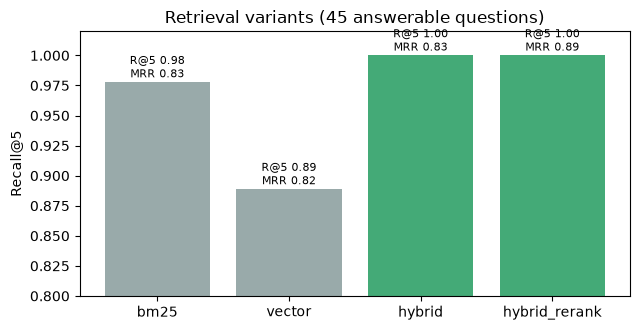

In [3]:
ret = pd.DataFrame(M["retrieval"]).T.loc[["bm25", "vector", "hybrid", "hybrid_rerank"]]
ret["ci_low"] = ret["ci"].map(lambda c: c[0]); ret["ci_high"] = ret["ci"].map(lambda c: c[1])
print(ret[["recall5", "ci_low", "ci_high", "mrr", "latency_ms"]].round(3).to_string())
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.bar(ret.index, ret["recall5"], color=["#9aa", "#9aa", "#4a7", "#4a7"])
ax.set_ylim(0.8, 1.02); ax.set_ylabel("Recall@5"); ax.set_title("Retrieval variants (45 answerable questions)")
for i, (v, m) in enumerate(zip(ret["recall5"], ret["mrr"])):
    ax.text(i, v + 0.004, f"R@5 {v:.2f}\nMRR {m:.2f}", ha="center", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "23_review_retrieval.png", dpi=130); plt.show()

**What we learned:** Combining the two searches pays off. Meaning search alone finds an answer-bearing piece in the top 5 for 89% of questions,
keyword search alone for 98%, and the merge for all 45 (100%). The helpfulness and verified-purchase re-rank did not change recall but
moved the first good piece higher (MRR 0.83 to 0.89). The 100% needs two warnings: the interval printed by the simple formula collapses to
[1.0, 1.0] and understates uncertainty with only 45 questions, and the answer patterns are lenient (a piece counts if it contains the
pattern, not if it fully answers). Retrieval is not the bottleneck; the next sections show where the real losses are. Latency for retrieval
is about 0.2 seconds per question, negligible next to the language model.

## 3. Aspect tagging: which topic is a review about?

**What we did.** Shoppers ask about a handful of recurring topics, so every review piece is tagged with any of six aspects: fit and size,
fabric and material, colour accuracy, quality and durability, comfort, delivery and packaging. The tags power the product summary
(section 6) and let a question be routed to a topic. We compared four methods and picked one *with a rule written down beforehand*:
the best macro-F1 (average of per-aspect F1) on a held-out half of 200 reviews that **a person labelled** (you, through a click page).
- **Keyword rules** (words such as "runs small", "washed", "arrived").
- **Embedding similarity** to a one-line description of each aspect.
- **Zero-shot NLI**: a small model (DeBERTa-v3-xsmall, 142 MB) asked "does this review talk about fit?".
- **Zero-shot local LLM**.
Thresholds were tuned on one half of the labels and every score is reported on the other half.

**Why.** If a simple rule is as good as a heavier model, it is cheaper, faster, and easier to explain to a catalog team.

           macro_f1_test  micro_f1_test  macro_f1_all  micro_f1_all  macro_precision_test  macro_recall_test  seconds_per_1000_chunks
rules              0.523          0.541         0.496         0.517                 0.626              0.491                    0.230
embedding          0.502          0.550         0.482         0.540                 0.442              0.664                  337.239
nli                0.585          0.654         0.587         0.667                 0.485              0.740                 7653.294
llm                0.427          0.415         0.422         0.422                 0.747              0.324                 4384.832

                    rules  embedding   nli   llm
fit_size             0.66       0.61  0.63  0.38
fabric_material      0.58       0.59  0.61  0.42
colour_accuracy      0.61       0.43  0.64  0.64
quality_durability   0.52       0.63  0.80  0.31
comfort              0.48       0.51  0.55  0.49
delivery_packaging   0.29       0.2

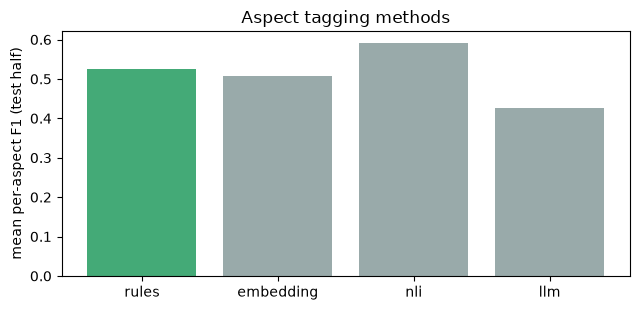

In [4]:
A = M["aspect"]
tab = pd.DataFrame(A["summary"]).T if isinstance(A["summary"], dict) else pd.DataFrame(A["summary"])
print(tab.round(3).to_string())
print()
pa = pd.DataFrame(A["per_aspect_test_f1"]).round(2); print(pa.to_string())
labels = pd.read_csv(OUT / "aspect_labels.csv"); names = [c for c in labels.columns if c != "chunk_id"]
print("\nlabelled reviews:", len(labels), "| ticked per aspect:", {c: int(labels[c].sum()) for c in names})
print("reviews with 2+ aspects:", int((labels[names].sum(axis=1) >= 2).sum()), "| with none:", int((labels[names].sum(axis=1) == 0).sum()))
print("\nNLI warm seconds per piece:", A["nli_warm_seconds_per_chunk"], "| NLI - rules macro-F1:", A["nli_minus_rules_macro_f1"])
print("chosen:", A["chosen"], "| best by the pre-set rule:", A["best_by_macro_f1_test"])
print(A["chosen_reason"])
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ms = A["summary"] if isinstance(A["summary"], dict) else None
vals = {k: v for k, v in zip(pa.columns, pa.mean())}
ax.bar(list(vals), list(vals.values()), color=["#4a7" if k == "rules" else "#9aa" for k in vals])
ax.set_ylabel("mean per-aspect F1 (test half)"); ax.set_title("Aspect tagging methods"); plt.tight_layout()
plt.savefig(FIG / "25_aspect_taggers.png", dpi=130); plt.show()

**What we learned:** On the held-out half, NLI scored highest (macro-F1 0.585) ahead of keyword rules (0.523), embeddings (0.502) and the
local LLM (0.427), so by our pre-set rule NLI "won". We did **not** use it, for two reasons we only found out by measuring: (1) NLI costs about
8.3 seconds per review piece on this CPU, which is about 16 days for all 166,607 pieces and about 8 hours even for the 20 products we
summarise, while keyword rules take milliseconds; (2) the gain over rules is +0.063 macro-F1 with a 95% bootstrap interval of
[-0.007, +0.133] on only 100 test pieces, so it may be noise. Rules were used. **Label quality is a limit too:** the labeller ticked "quality and durability" on 144 of 200 pieces
and 136 of 200 carry two or more aspects, so the labels are liberal and every method's recall looks low against them. Delivery has only 14
positives, so its F1 (about 0.3 for every method) is not trustworthy.

## 4. The question-answering pipeline and its safety gate

**What we did.** For a question about a product: (1) retrieve and re-rank that product's review pieces; (2) a **gate** decides whether
there is enough evidence; (3) if yes, the local model writes the answer; (4) the answer is validated.
- **Evidence gate.** At least 2 *different* reviews must be similar enough to the question (cosine similarity at or above a threshold).
  If not, the system answers "Not enough reviews mention this." and the language model is **never called** (saves 20 to 100 seconds too).
- **Answer format.** The model must return JSON: `answer`, `citations` (review ids), `reviewers_agree`, `reviewers_disagree`, and whether
  it can answer. Review ids appear inline like `[R94697]`. The code adds `confidence`, `aspect` and `evidence_count`.
- **Citation check.** Any review id the model quotes that was not shown to it is removed and counted. An answer left with no valid
  citation becomes a refusal.

**Choosing the gate threshold.** This is the one number that trades "answers too eagerly" against "refuses too often". We first tuned it
on 24 development questions and tested on the other 36 as planned. It did not generalise, so we switched to cross-validation.

planned approach: tune on 24 dev questions -> threshold 0.58
   dev  (answer rate, refuse rate): [0.75, 1.0]
   test (answer rate, refuse rate): [0.45, 0.86]
product-grouped 5-fold CV: fold thresholds [0.52, 0.52, 0.58, 0.58, 0.52] -> answer rate 0.6 refuse rate 0.82
final threshold fit on all 60: 0.52 -> {'answer_rate': 0.69, 'refuse_rate': 0.8, 'balanced_acc': 0.74}


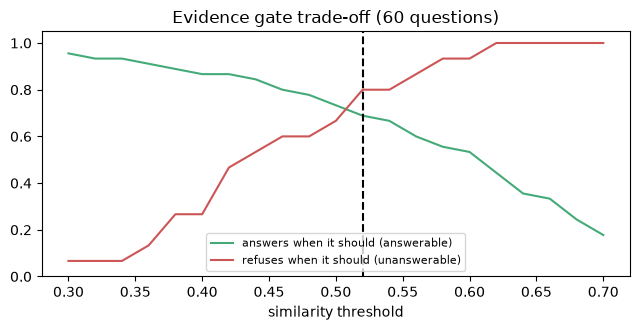

In [5]:
G = M["gate"]
print("planned approach: tune on 24 dev questions -> threshold", G["dev_tuned_threshold"])
print("   dev  (answer rate, refuse rate):", [round(x, 2) for x in G["dev_tuned_dev_to_test"]["dev"]])
print("   test (answer rate, refuse rate):", [round(x, 2) for x in G["dev_tuned_dev_to_test"]["test"]])
cv = G["cross_validated"]
print("product-grouped 5-fold CV: fold thresholds", cv["fold_thresholds"], "-> answer rate", round(cv["answer_rate"], 2), "refuse rate", round(cv["refuse_rate"], 2))
print("final threshold fit on all 60:", G["min_similarity"], "->", {k: round(v, 2) for k, v in G["fit_on_all_60"].items()})

ret_pkl = pd.read_pickle(OUT / "retrieval.pkl")
final = ret_pkl[ret_pkl["variant"] == "hybrid_rerank"]
grid = np.round(np.arange(0.30, 0.71, 0.02), 2)
rows = [(t, *gate_rates(final, t, cfg["retrieval"]["min_supporting"])) for t in grid]
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(grid, [r[1] for r in rows], label="answers when it should (answerable)", color="#4a7")
ax.plot(grid, [r[2] for r in rows], label="refuses when it should (unanswerable)", color="#c55")
ax.axvline(G["min_similarity"], ls="--", color="k"); ax.set_xlabel("similarity threshold"); ax.set_ylim(0, 1.05)
ax.legend(fontsize=8); ax.set_title("Evidence gate trade-off (60 questions)"); plt.tight_layout()
plt.savefig(FIG / "24_evidence_gate.png", dpi=130); plt.show()

**What we learned:** The planned approach looked fine on its own tuning questions (it answered 75% of answerable and refused 100% of
unanswerable ones) and **fell apart on the unseen questions**: it answered only 45% of answerable ones. That is a classic overfit on 24 questions. With
product-grouped cross-validation (a product never appears in both the tuning and the testing folds) the expected behaviour at threshold
0.52-0.58 is: answer about 60% of answerable questions, refuse about 82% of unanswerable ones. The curve shows the gate is a
**weak discriminator**: no threshold gives both rates near 90%, because "similar text" is not the same as "answers the question".
The final threshold (0.52) was fit on all 60 questions, so the end-to-end numbers below are slightly optimistic.

## 5. End-to-end results on 60 questions

**What we did.** Ran every question through the full pipeline (model `llama3.2:3b` on CPU) and measured, using the saved answers:
- **Correct-refusal rate**: unanswerable questions that got "Not enough reviews mention this".
- **False-refusal rate**: answerable questions that were refused (the cost of caution).
- **Citation accuracy**: (a) *validity* = quoted ids that exist among the retrieved reviews; (b) *relevance* = quoted reviews that contain
  the answer pattern.
- **Faithfulness**: a second pass with the same local model splits an answer into claims and asks "is this claim stated in the reviews it
  cites?" (yes/no). It is the same model that wrote the answer and the check is strict, so we **hand-verified 15 answers** (see below).
- **Latency** per question.

In [6]:
E = M["end_to_end"]
show = {
    "answerable / unanswerable questions": f"{E['n_answerable']} / {E['n_unanswerable']}",
    "correct refusal rate (unanswerable)": f"{E['correct_refusal_rate']:.1%}  ({15 - E['unanswerable_answered']} of 15)",
    "false refusal rate (answerable)": f"{E['false_refusal_rate']:.1%}  ({45 - E['answered_answerable']} of 45)",
    "citations kept / invalid ids": f"{E['citations_kept']} / {E['invalid_citation_ids']}",
    "citation validity": f"{E['citation_validity']:.1%}",
    "citation relevance (cited review has the answer)": f"{E['citation_relevance']:.1%}",
    "judge: fully faithful answers": f"{E['faithful_answers']:.1%} of {E['judged_answers']}",
    "judge: claims supported": f"{E['claim_support_rate']:.1%}",
    "mean confidence of answered": f"{M['mean_confidence_answered']:.2f}",
    "latency: answered / refused (s)": f"{E['latency_answered_mean_s']:.1f} / {E['latency_refused_mean_s']:.1f}",
}
print(pd.Series(show).to_string())

v1 = [json.loads(x) for x in (OUT / "answers_v1.jsonl").read_text(encoding="utf-8").splitlines()]
v1_false = np.mean([a["output"]["refused"] for a in v1 if a["kind"] == "answerable"])
print(f"\nfirst version of the pipeline (before the citation-parsing fix): false refusal {v1_false:.0%}")

answerable / unanswerable questions                           45 / 15
correct refusal rate (unanswerable)                 93.3%  (14 of 15)
false refusal rate (answerable)                     31.1%  (14 of 45)
citations kept / invalid ids                                   99 / 0
citation validity                                              100.0%
citation relevance (cited review has the answer)                84.8%
judge: fully faithful answers                             40.6% of 32
judge: claims supported                                         56.7%
mean confidence of answered                                      0.89
latency: answered / refused (s)                            38.5 / 1.9

first version of the pipeline (before the citation-parsing fix): false refusal 82%


**What we learned:** The safety side works: 14 of 15 unanswerable questions were refused (93%), no invented review ids slipped
through (0 of 99 cited ids invalid), and 85% of cited reviews actually contain the answer pattern. The cost is helpfulness: 14 of 45 answerable questions
(31%) were refused, and answered questions take about 39 seconds on this CPU versus 2 seconds for a refusal (refusals skip the model).
**The first version refused 82% of answerable questions.** Cause: the model often wrote ids as `[R1, R2]` or listed them only in
a separate field, and our parser treated both as "no citation", turning good answers into refusals. Fixing the parser (extract ids from
anywhere, strip only invalid ones) and adding tests took false refusals from 82% to 31%. The lesson: an unvalidated strict rule can look
like a safe model but is really a broken one.

**On the judge:** only 41% of answers pass the claim-level judge, which sounds alarming. The 15-answer hand-check (next section) suggests the
judge is the bigger problem.

## 6. Can we trust the faithfulness judge? (hand-check of 15 answers)

**What we did.** You rated 15 answers blind, chosen about half from answers the judge passed and half from answers it failed, and said for each whether
every claim was supported by the cited reviews. We compare your ratings with the judge.

In [7]:
H = M["handcheck"]
print(f"answers hand-checked: {H['n']}")
print(f"judge agrees with the human: {H['agreement']:.0%}")
print(f"human rated faithful: {H['human_faithful_rate']:.0%}  (14 of 15)")
print(f"judge flagged {H['judge_flagged']}; the human overturned {H['judge_flagged_overturned']}")
print(f"judge passed but human rejected: {H['judge_passed_human_rejected']}")
n_pass = round(E["faithful_answers"] * E["judged_answers"]); n_fail = E["judged_answers"] - n_pass
est = (n_pass / E["judged_answers"]) * 1.0 + (n_fail / E["judged_answers"]) * (6 / 7)
print(f"\nreweighted estimate of the true faithful rate (judge strata {n_pass} pass / {n_fail} fail; human faithful 8 of 8 and 6 of 7): about {est:.0%}")

answers hand-checked: 15
judge agrees with the human: 60%
human rated faithful: 93%  (14 of 15)
judge flagged 7; the human overturned 6
judge passed but human rejected: 0

reweighted estimate of the true faithful rate (judge strata 13 pass / 19 fail; human faithful 8 of 8 and 6 of 7): about 92%


**What we learned:** The judge and the human agreed on only 9 of 15 answers (60%). The disagreement runs one way: the judge never passed an answer the
human rejected, but it flagged 7 and the human overturned 6 of them. So the judge is **too strict**, mainly because it checks short summary lines such as
"The chain or clasp breaks easily" against two reviews on their own, and fails them when the reviews say it more gently. The human-checked
sample was 93% faithful (14 of 15). Re-weighting by how many answers sit in each judge group gives a rough true faithful rate of about 92%, but with only 15 ratings and one rater
that estimate is very uncertain (we did not compute an interval, and it would be wide). We therefore report the judge's 41% as a **lower bound**, the human result as a small-sample
check, and do not claim 92% as a measured number. The judge is the same 3B model that writes the answers, so a stronger independent judge is a
listed next step.

## 7. What good answers, a refusal, and a failure look like

**Why.** Aggregate numbers hide how the system behaves on a real question, so here are four real cases from the 60.

In [8]:
def show_case(qid, with_reviews=0):
    a = by_id[qid]; o = a["output"]
    print(f"[{qid}] {a['q']}   ({a['kind']}, product {a['item']})")
    print("  answer :", o["answer"])
    print("  agree  :", o["reviewers_agree"], "| disagree:", o["reviewers_disagree"] or "-")
    print(f"  refused={o['refused']} confidence={o['confidence']} aspect={o['aspect']} evidence_count={o['evidence_count']} top_similarity={a['top_similarity']:.2f}")
    print("  judge faithful:", judge.get(qid, {}).get("faithful", "n/a (refused)"))
    for r in o["citations"][:with_reviews]:
        print(f"    {r}: {text_of[r][:260]!r}")
    print()

print("GOOD ANSWER 1 - reviewers disagree, and the answer says so")
show_case("Q01", with_reviews=3)
print("GOOD ANSWER 2 - strong agreement, five citations")
show_case("Q02")
print("CORRECT REFUSAL - nothing in the reviews about a sports bra")
show_case("Q09")

GOOD ANSWER 1 - reviewers disagree, and the answer says so
[Q01] Does this shirt run big or small? Should I size up?   (answerable, product B0BYCZ2W78)
  answer : Most reviewers say it runs a bit big, with some finding it true to size [R94697], but a half size larger [R94416].
  agree  : It runs a bit big [R94577][R94416]. | disagree: Some reviewers found it true to size [R94697].
  refused=False confidence=0.9 aspect=fit_size evidence_count=4 top_similarity=0.64
  judge faithful: True
    R94577: "Fits a little big. I'm not sure if it fits big or I ordered it too big...I do like that I have a little room in it since I'm not a fan of tight fit shirt"
    R94416: 'Better Than Expected. As others have stated it runs maybe a 1/2 size larger? I can comfortably wear 4XL in these types of shirts but based on reviews here I went with the 3XL, and it fits just as nicely as a 4XL would. Sleeves are long enough that they do not '
    R94697: "comfortable and true to size (3XL). I'm a big guy and

**What we learned:** In the fit question (Q01) the model reports a split honestly: most say a bit big, one says true to size, and it cites
the review for each side so a shopper can click through. In the cooling question (Q02) five reviews agree and confidence is 1.0. For
"does the skort have a built-in sports bra?" (Q09) the best matching reviews had similarity 0.49, below the 0.52 bar, so the system answered
"Not enough reviews mention this." in about two seconds, without calling the model. That is exactly the behaviour we want.

### The one failure to learn from: Q27, "Does the pocket watch come in a gift box?"
Q27 was labelled **unanswerable** and the system answered "Most reviewers say it comes in a gift box" citing two reviews. Let us look at
why.

In [9]:
show_case("Q27", with_reviews=2)
q27 = next(q for q in load_questions() if q["id"] == "Q27")
print("rule that labelled it unanswerable:", q27["absent"])

[Q27] Does the pocket watch come in a gift box?   (unanswerable, product B00C54QX3M)
  answer : Most reviewers say it comes in a gift box [R128266][R128237].
  agree  : It comes in a gift box [R128266][R128237]. | disagree: -
  refused=False confidence=0.77 aspect=delivery_packaging evidence_count=3 top_similarity=0.58
  judge faithful: True
    R128266: 'A great gift. A wonderful watch. Our grandson loved it. Being able to watch the movement fascinating to him. The watch was well made and came in its own special "fancy" box.'
    R128237: "... his pocket watch twice as a gift the guy love them! They are really beautiful. I've given his pocket watch twice as a gift the guy love them ! They are really beautiful !"

rule that labelled it unanswerable: gift box|presentation box


**Root cause.** Three things went wrong together, in order of importance. (1) **Retrieval matched the word, not the meaning.** The question says "gift
box"; one cited review (R128237) says only that the watch was given "as a gift", which says nothing about a box, and it was still shown as evidence. (2) **The model
over-generalised.** It turned two reviews, only one of which is relevant, into "most reviewers say". (3) **The checks were too lenient here.** The gate passed because
the best match scored 0.58 (bar 0.52) with 3 supporting reviews, and the judge passed the answer. In fairness, the other cited review (R128266) says the watch
"came in its own special 'fancy' box", which our unanswerable label (the pattern "gift box|presentation box") did not catch, so the question was not as clearly
unanswerable as we labelled it. The system's answer was half right and its wording ("most reviewers") was wrong. Fixes to try next: require the *key noun* of the question
("box") to appear in a cited review, and phrase the number of supporting reviews exactly ("2 reviews") rather than "most".

## 8. Product summaries where the numbers come from code

**What we did.** For each of the 20 test products and each aspect with at least 5 mentions, **code** computes: how many reviews mention it, and
the share that are positive (4-5 stars), mixed (3) and negative (1-2 stars), plus, for fit, how many say it runs small, large or true to size. The
language model is only asked to phrase one sentence per aspect from those numbers. Each sentence is then checked: if it contains any number that is not in that
aspect's facts, it is thrown away and replaced by a plain template sentence built straight from the numbers.

**Why.** Language models are poor at arithmetic and eager to round. Letting code own the numbers means a shopper never sees "90% say it runs small" unless
the data says so. The sentiment is rating-based: it is not a judgement of the review text.

In [10]:
S = json.loads((OUT / "summaries.json").read_text(encoding="utf-8"))
print("aspect tagger used:", S["method"], "| sources:", M["summary_sources"])
ex = [p for p in S["products"].values() if p["facts"]["aspects"].get("fit_size")][:1] + [p for p in S["products"].values() if p["source"] == "mixed"][:1]
for p in ex:
    print("\n", p["title"][:90], "| source:", p["source"], "| fallback aspects:", p["bad_aspects"])
    print(" facts  :", {a: (e["mentions"], e["pct_positive"], e["pct_negative"]) for a, e in p["facts"]["aspects"].items()})
    print(" summary:", p["summary"])

aspect tagger used: rules | sources: {'llm': 18, 'template': 1, 'mixed': 1}

 niceeshop(TM) Vintage Glazed Lady Cat Pendant Long Chain Necklace,Black | source: llm | fallback aspects: []
 facts  : {'fit_size': (14, 57, 14), 'fabric_material': (13, 54, 15), 'colour_accuracy': (30, 77, 10), 'quality_durability': (84, 37, 39), 'comfort': (14, 57, 14), 'delivery_packaging': (47, 62, 28)}
 summary: Fit and size: 14 reviews mention it, with 57% positive, 29% mixed, and 14% negative, averaging 3.7 stars. Fabric and material: 13 reviews mention it, with 54% positive, 31% mixed, and 15% negative, averaging 3.6 stars. Colour: 30 reviews mention it, with 77% positive, 13% mixed, and 10% negative, averaging 4.0 stars. Quality and durability: 84 reviews mention it, with 37% positive, 24% mixed, and 39% negative, averaging 3.0 stars. Comfort: 14 reviews mention it, with 57% positive, 29% mixed, and 14% negative, averaging 3.6 stars. Delivery and packaging: 47 reviews mention it, with 62% positive, 1

**What we learned:** Of 20 product summaries, 18 were fully phrased by the model, 1 mixed in a template sentence after a number check failed, and 1
fell back entirely to the template. The number guard is not decoration: in an earlier run the model attached a number to the wrong aspect (a
"fabric" percentage written next to "comfort"), which is why the check is per aspect and why the aspect label is added by code. A second fix came from reading these outputs: the model sometimes repeated the aspect label itself, giving
"Comfort: Comfort: ...", so the code now strips a repeated label (with a test). Because the aspect
tags come from keyword rules, a review that mentions "size" is counted under fit even if it is not about fit, so the percentages describe
*reviews that mention the topic*, not the product's quality on that topic.

## 9. What this means, and what we would do next

**Conclusions.**
1. **Retrieval is solved enough; answering is where the risk is.** Searching one product's reviews with keyword plus meaning search finds the
   answer in the top 5 for all 45 answerable questions, but the evidence gate that decides "answer or refuse" is a weak discriminator and was tuned on few questions.
2. **Refusing is easy to make safe and hard to make useful.** 93% of unanswerable questions were correctly refused, at the price of refusing 31% of answerable ones.
3. **The automatic judge is not trustworthy as built.** It is the same small model and is too strict (60% agreement with the human, 6 of 7 flags overturned),
   so its 41% faithful rate is a lower bound, not a measurement. A hand-checked rate of 14 of 15 is encouraging but tiny.
4. **Simple beat clever for aspect tagging, for a practical reason.** The heavier NLI model scored a little higher but takes about 8 seconds per piece and its gain may be noise.

**Limits to keep in mind.**
- 60 questions on 20 products, designed and tuned on the same set; the gate threshold was fit on all 60.
- The test-set answers were decided by word patterns written by the developer; they are cheap and repeatable but imperfect (see Q27).
- The aspect labels came from one person and are liberal; three of the six aspects have too few positives to trust per-aspect scores.
- One 3B model on CPU: roughly 39 seconds per answered question is too slow for live use without a faster model, a GPU or caching.

**Next steps.** Require the key noun of the question in a cited review; say "2 reviews" instead of "most"; try `qwen2.5:3b` or a hosted model through the
same `LLMClient` interface as an independent judge; label 100 more questions; and surface the `confidence` and citations in the Streamlit app so a shopper
can click through to the reviews.